# The Most Efficient NBA Duo: Application
**MIS 433 Course Project | Sam Nocera & Jackson Hardy | Fall 2026**

This notebook turns our analysis into an application with three features. Each feature:
1. takes **input from the user**,
2. pulls data from **our scored dataset** (built in `01_analysis.ipynb`) and the **BALLDONTLIE API** (live NBA teams, players and games),
3. uses the **OpenAI API** to generate text, audio, or an image.

| Feature | User input | Dataset | BALLDONTLIE API | OpenAI output |
|---|---|---|---|---|
| 1. Team Duo Scouting Report | a team | team's top duos | 2026-27 record and recent games | written report + audio narration |
| 2. Duo vs Duo | two duos | both duos' stats | player profiles | written verdict |
| 3. Build Your Own Model | stat weights | all duos re-scored | team name | written explanation + award poster image |


## Setup

**API keys:** on Colab, open Secrets (key icon) in the left sidebar and add two secrets with notebook access turned on:
- `OpenAIAPI` (your OpenAI API key)
- `BalldontlieAPI` (free account at app.balldontlie.io)

In [1]:
# Install the OpenAI package if you haven't yet
#!pip install --upgrade openai

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import json
import time
from sklearn.preprocessing import MinMaxScaler

In [3]:
from google.colab import userdata
openai_api_key = userdata.get('OpenAIAPI').strip()      # strip() removes extra spaces or line breaks
bdl_api_key = userdata.get('BalldontlieAPI').strip()

In [4]:
from openai import OpenAI

client = OpenAI(api_key=openai_api_key)

### Load our scored dataset

In [5]:
data_url = 'https://raw.githubusercontent.com/samnocera05-ui/mis433/main/final-project/data/'

duos = pd.read_csv(data_url + 'duos_scored_2025_26.csv')        # 2025-26, scored in 01_analysis
duos_new = pd.read_csv(data_url + 'duos_clean_2026_27.csv')     # 2026-27 so far, cleaned
print(duos.shape, duos_new.shape)
duos.head()

(1259, 18) (904, 19)


,Lineups,Player_1,Player_2,TEAM,GP,MIN,OffRtg,DefRtg,NetRtg,TS%,AST/TO,REB%,PIE,DES_Balanced,DES_Offense,DES_Defense,DES_Impact,Team_Rank
0,K. Durant - A. Thompson,K. Durant,A. Thompson,HOU,76,2157,117.0,111.6,5.4,58.5,1.74,55.2,54.0,53.741198,52.007902,56.155100,58.368545,18.0
1,J. Smith Jr. - A. Thompson,J. Smith Jr.,A. Thompson,HOU,75,2130,117.4,111.5,5.9,58.2,1.78,54.6,53.4,53.714527,52.095119,55.356489,57.520959,19.0
2,K. Durant - J. Smith Jr.,K. Durant,J. Smith Jr.,HOU,74,2034,117.7,112.3,5.4,58.4,1.76,54.6,53.6,53.325924,52.379401,54.337049,57.535211,22.0
3,A. Sengun - A. Thompson,A. Sengun,A. Thompson,HOU,70,1978,117.6,112.3,5.3,58.7,1.81,54.2,53.7,53.496111,53.014805,53.784915,57.663062,20.0
4,N. Alexander-Walker - J. Johnson,N. Alexander-Walker,J. Johnson,ATL,71,1978,115.8,111.0,4.8,59.5,2.30,48.9,52.3,52.550153,54.615409,46.825221,54.343981,14.0


### Helper functions

**OpenAI** (same pattern as our class notebook `openai-api-basics`): text, text-to-speech, and image generation.

In [6]:
def get_completion(prompt, model="gpt-6-luna"):
    messages = [
        {"role": "system", "content": "You are an NBA analytics expert. Be specific, use the numbers you are given, and keep it short."},
        {"role": "user", "content": prompt}
    ]
    response = client.chat.completions.create(
        model=model,
        messages=messages,
    )
    return response.choices[0].message.content

In [7]:
from IPython.display import Audio, Image, Markdown, display
import base64

def text_to_speech(text, voice="onyx"):
    response = client.chat.completions.create(
        model="gpt-audio-1.5",
        modalities=["text", "audio"],
        audio={"voice": voice, "format": "wav"},
        messages=[
            {"role": "system", "content": "You are an NBA broadcast narrator. Read the user's text exactly as written. Do not add commentary."},
            {"role": "user", "content": text}
        ]
    )
    return base64.b64decode(response.choices[0].message.audio.data)

def generate_image(prompt):
    result = client.images.generate(
        model="gpt-image-2.5-flare",
        prompt=prompt,
        size="1024x1024",
        quality="low"
    )
    return base64.b64decode(result.data[0].b64_json)

**BALLDONTLIE API** (same pattern as our class notebook `api-basics`: `requests.get`, check `response.ok`, read `response.json()`).

The free tier allows 5 requests per minute, so the helper waits 12 seconds after each call.

In [8]:
BDL_URL = 'https://api.balldontlie.io/v1/'

def bdl_get(endpoint, params=None):
    response = requests.get(BDL_URL + endpoint, headers={'Authorization': bdl_api_key}, params=params)
    time.sleep(12)   # free tier: 5 requests per minute
    if response.ok:
        return response.json()
    else:
        print(f"Request to {endpoint} failed with status code {response.status_code}")
        return None

In [9]:
# Get all 30 teams once and keep them in a dataframe
data = bdl_get('teams')
teams = pd.DataFrame(data['data'])
teams = teams[teams['id'] <= 30]    # ids above 30 are historical franchises
teams[['id', 'abbreviation', 'full_name', 'conference', 'division']].head()

,id,abbreviation,full_name,conference,division
0,1,ATL,Atlanta Hawks,East,Southeast
1,2,BOS,Boston Celtics,East,Atlantic
2,3,BKN,Brooklyn Nets,East,Atlantic
3,4,CHA,Charlotte Hornets,East,Southeast
4,5,CHI,Chicago Bulls,East,Central


In [10]:
def get_team_games(team_abbr, season=2026):
    # season=2026 means the 2026-27 season
    team_id = int(teams[teams['abbreviation'] == team_abbr]['id'].iloc[0])
    data = bdl_get('games', params={'team_ids[]': team_id, 'seasons[]': season, 'per_page': 100})
    games = []
    for g in data['data']:
        if g['status'] == 'Final':
            home = g['home_team']['abbreviation'] == team_abbr
            team_score = g['home_team_score'] if home else g['visitor_team_score']
            opp_score = g['visitor_team_score'] if home else g['home_team_score']
            opponent = g['visitor_team']['abbreviation'] if home else g['home_team']['abbreviation']
            games.append({'date': g['date'], 'opponent': opponent, 'home': home,
                          'team_score': team_score, 'opp_score': opp_score,
                          'result': 'W' if team_score > opp_score else 'L'})
    games = pd.DataFrame(games)
    if len(games) > 0:
        games = games.sort_values('date', ascending=False)
    return games

In [11]:
# Player names in our data look like 'N. Jokić' or 'J. Smith Jr.'.
# BALLDONTLIE stores names without accents, so we replace accented letters first.
accents = {'ć': 'c', 'č': 'c', 'é': 'e', 'á': 'a', 'í': 'i', 'ó': 'o', 'ö': 'o', 'ü': 'u', 'š': 's', 'ž': 'z', 'ņ': 'n', 'ģ': 'g', 'ū': 'u'}

def get_player(short_name, team_abbr):
    for letter, plain in accents.items():
        short_name = short_name.replace(letter, plain)
    first_initial = short_name.split('. ')[0]
    last_name = short_name.split('. ')[1].split(' ')[0]     # 'Smith Jr.' -> 'Smith'

    data = bdl_get('players', params={'search': last_name, 'per_page': 100})
    if data is None:
        return None
    for p in data['data']:
        if p['first_name'].startswith(first_initial) and p['team'] is not None and p['team']['abbreviation'] == team_abbr:
            return {'name': p['first_name'] + ' ' + p['last_name'], 'position': p['position'], 'height': p['height'],
                    'draft_year': p['draft_year'], 'country': p['country']}
    # Player may have changed teams since 2025-26: fall back to the first name match
    for p in data['data']:
        if p['first_name'].startswith(first_initial):
            return {'name': p['first_name'] + ' ' + p['last_name'], 'position': p['position'], 'height': p['height'],
                    'draft_year': p['draft_year'], 'country': p['country'],
                    'current_team': p['team']['abbreviation'] if p['team'] is not None else 'free agent'}
    return None

## Feature 1: Team Duo Scouting Report

**Purpose:** a coach or fan picks a team and gets a scouting report on its most efficient duos, read aloud like a broadcast segment.

**How it works:**
1. **Input:** a team abbreviation
2. **Dataset:** the team's top 3 duos from 2025-26 (Balanced model) and its best duo so far in 2026-27
3. **BALLDONTLIE API:** the team's 2026-27 record and last 5 games
4. **OpenAI:** writes the report (text), then narrates it (audio)

In [12]:
def team_scouting_report(team_abbr):
    # 1. Dataset: top 3 duos last season, best duo this season
    top3 = duos[duos['TEAM'] == team_abbr].sort_values('DES_Balanced', ascending=False).head(3)
    this_season = duos_new[duos_new['TEAM'] == team_abbr].sort_values('NetRtg', ascending=False).head(3)

    # 2. API: record and recent games
    games = get_team_games(team_abbr)
    wins = (games['result'] == 'W').sum()
    losses = (games['result'] == 'L').sum()
    team_name = teams[teams['abbreviation'] == team_abbr]['full_name'].iloc[0]

    print(f"{team_name}: {wins}-{losses} in 2026-27")
    print('\nTop 3 duos, 2025-26 (Balanced model):')
    display(top3[['Lineups', 'MIN', 'OffRtg', 'DefRtg', 'NetRtg', 'DES_Balanced']].round(1))
    print('Best duos so far in 2026-27 (100+ minutes):')
    display(this_season[['Lineups', 'MIN', 'NetRtg']])
    print('Last 5 games:')
    display(games.head(5))

    # 3. OpenAI: written report
    prompt = f"""
    Write a scouting report (about 150 words) on the {team_name}'s most efficient two-player duos.
    Duo Efficiency Score (DES) is 0-100; higher is better. Net Rating is points per 100 possessions.

    Top 3 duos last season (2025-26):
    {top3[['Lineups', 'MIN', 'OffRtg', 'DefRtg', 'NetRtg', 'DES_Balanced']].round(1).to_string(index=False)}

    Best duos so far this season (2026-27):
    {this_season[['Lineups', 'MIN', 'NetRtg']].to_string(index=False)}

    Record this season: {wins}-{losses}. Last 5 games:
    {games.head(5).to_string(index=False)}

    Say why the top duo works (offense, defense, or both), whether it is still producing this season,
    and one lineup recommendation for the coach.
    """
    report = get_completion(prompt)
    display(Markdown(report))

    # 4. OpenAI: audio narration
    display(Audio(text_to_speech(report), autoplay=False))
    return report

In [13]:
team = 'SAS'
# Or replace this with:
# team = input("Enter a team abbreviation (e.g., SAS, BOS, DEN): ").upper()

report_1 = team_scouting_report(team)

San Antonio Spurs: 15-3 in 2026-27

Top 3 duos, 2025-26 (Balanced model):


,Lineups,MIN,OffRtg,DefRtg,NetRtg,DES_Balanced
613,V. Wembanyama - D. Harper,560,120.9,93.9,27.0,84.5
194,D. Vassell - V. Wembanyama,1003,123.3,102.4,20.9,77.2
102,J. Champagnie - V. Wembanyama,1231,122.1,101.7,20.4,75.8


Best duos so far in 2026-27 (100+ minutes):


,Lineups,MIN,NetRtg
222,D. Fox - D. Harper,249.0,36.9
313,K. Johnson - V. Wembanyama,216.0,36.8
54,D. Fox - V. Wembanyama,367.0,34.8


Last 5 games:


,date,opponent,home,team_score,opp_score,result
17,2026-11-23,SAC,False,123,107,W
16,2026-11-21,NOP,True,114,91,W
15,2026-11-19,LAC,True,124,112,W
14,2026-11-17,DET,True,93,105,L
13,2026-11-15,UTA,False,110,102,W


**Scouting report:** San Antonio’s strongest duo last season was Victor Wembanyama and Dylan Harper. Its 84.5 DES came with a 120.9 offensive rating and a 93.9 defensive rating, producing a +27.0 net rating across 560 minutes. That points to impact at both ends: highly productive offense paired with elite defense, with Wembanyama anchoring the defensive results.

The exact pairing’s current-season performance isn’t provided, so it’s not possible to confirm it is still producing together. Still, both players feature in strong current duos: Harper with De’Aaron Fox (+36.9 over 249 minutes), and Wembanyama with Fox (+34.8 over 367 minutes) or Keldon Johnson (+36.8 over 216 minutes). The Spurs are 15–3 and have won four of their last five.

**Recommendation:** Make Fox–Wembanyama the primary lineup pairing for now; it has the largest reported sample among this season’s top duos and remains highly effective.

## Feature 2: Duo vs Duo

**Purpose:** compare any two duos head-to-head and get a verdict on which one is more efficient and why.

**How it works:**
1. **Input:** two duo names (from the `Lineups` column) or two team abbreviations (uses each team's best duo)
2. **Dataset:** both duos' stats and league ranks under all four models
3. **BALLDONTLIE API:** profiles of all four players (position, height, draft year, country)
4. **OpenAI:** writes the verdict

In [14]:
def find_duo(name_or_team):
    # A team abbreviation returns that team's best duo; otherwise look up the duo by name
    if name_or_team in list(duos['TEAM']):
        return duos[duos['TEAM'] == name_or_team].sort_values('DES_Balanced', ascending=False).iloc[0]
    return duos[duos['Lineups'] == name_or_team].iloc[0]


def duo_vs_duo(duo_a_input, duo_b_input):
    a = find_duo(duo_a_input)
    b = find_duo(duo_b_input)

    # 1. Dataset: side-by-side stats
    stats = ['MIN', 'OffRtg', 'DefRtg', 'NetRtg', 'TS%', 'AST/TO', 'REB%', 'PIE', 'DES_Balanced', 'DES_Offense', 'DES_Defense', 'DES_Impact']
    compare = pd.DataFrame({a['Lineups'] + ' (' + a['TEAM'] + ')': a[stats], b['Lineups'] + ' (' + b['TEAM'] + ')': b[stats]})
    display(compare.round(1))

    # Chart: the four model scores side by side
    scores = compare.loc[['DES_Balanced', 'DES_Offense', 'DES_Defense', 'DES_Impact']].reset_index()
    scores = scores.melt(id_vars=['index'], var_name='Duo', value_name='Score')
    scores['index'] = scores['index'].str.replace('DES_', '')
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.barplot(data=scores, x='index', y='Score', hue='Duo', ax=ax)
    ax.set_xlabel('Model')
    ax.set_ylabel('Duo Efficiency Score (0-100)')
    ax.set_title('Duo vs Duo: score under each model')
    ax.legend(loc='lower left')
    plt.show()

    # 2. API: player profiles
    profiles = []
    for duo in [a, b]:
        for player in [duo['Player_1'], duo['Player_2']]:
            info = get_player(player, duo['TEAM'])
            if info is not None:
                profiles.append(info)
    profiles = pd.DataFrame(profiles)
    display(profiles)

    # 3. OpenAI: verdict
    prompt = f"""
    Compare these two NBA duos from the 2025-26 season. DES = Duo Efficiency Score (0-100, higher is better)
    under four weighting models. Net Rating = points per 100 possessions.

    {compare.to_string()}

    Player profiles:
    {profiles.to_string(index=False)}

    In about 120 words: which duo is more efficient overall, where each one is stronger (offense, defense,
    rebounding, shooting), how the player types explain it, and whether the answer changes by model.
    """
    verdict = get_completion(prompt)
    display(Markdown(verdict))
    return verdict

,V. Wembanyama - D. Harper (SAS),A. Gordon - N. Jokić (DEN)
MIN,560,650
OffRtg,120.9,129.7
DefRtg,93.9,111.6
NetRtg,27.0,18.1
TS%,62.7,64.8
AST/TO,2.28,3.22
REB%,56.5,55.1
PIE,65.6,59.8
DES_Balanced,84.528737,80.061581
DES_Offense,73.98195,88.195515


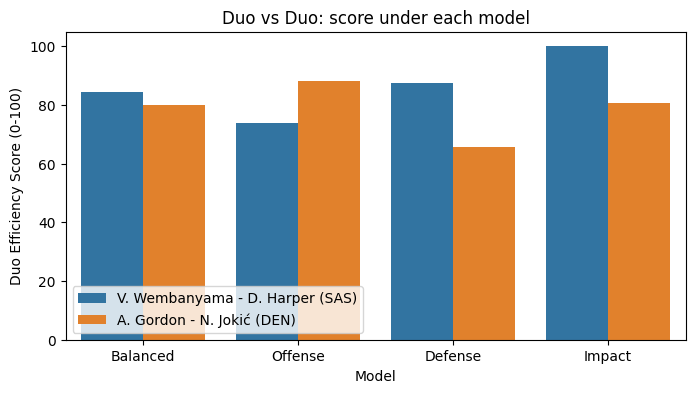

,name,position,height,draft_year,country
0,Victor Wembanyama,F-C,7-4,2023,France
1,Dylan Harper,G,6-5,2025,USA
2,Aaron Gordon,F,6-8,2014,USA
3,Nikola Jokic,C,6-11,2014,Serbia


San Antonio is more efficient overall under the balanced model: Wembanyama–Harper scores 84.53 DES versus 80.06 for Gordon–Jokić. Its Net Rating is also higher, +27.0 versus +18.1. Denver’s strength is offense: its offense DES is 88.20 versus 73.98, with better OffRtg (129.7 to 120.9), TS% (64.8% to 62.7%) and AST/TO (3.22 to 2.28). San Antonio leads on defense (DefRtg 93.9 to 111.6; defense DES 87.34 to 65.60) and rebounding (56.5% to 55.1%). That fits Wembanyama’s rim protection and size, paired with Harper’s guard skills; Denver pairs Jokić’s elite playmaking and efficient scoring with Gordon’s athleticism. The answer depends on the model: Denver wins offense, but San Antonio wins balanced, defense and impact (99.92 to 80.67).

In [15]:
duo_a = 'SAS'
duo_b = 'DEN'
# Or replace these with:
# duo_a = input("First duo (e.g., 'A. Gordon - N. Jokić') or team abbreviation: ")
# duo_b = input("Second duo or team abbreviation: ")

verdict_2 = duo_vs_duo(duo_a, duo_b)

## Feature 3: Build Your Own Model

**Purpose:** the user decides what "efficient" means by choosing the stat weights. The app re-scores every duo, shows how the rankings change compared with our Balanced model, explains the result, and creates an award poster for the winner.

**How it works:**
1. **Input:** a weight for each stat (any positive numbers; they are scaled to add up to 1)
2. **Dataset:** all 2025-26 duos re-scored with `MinMaxScaler` and the user's weights
3. **BALLDONTLIE API:** the winning team's full name, conference and division
4. **OpenAI:** explains the result (text) and generates a "Duo of the Year" poster (image)

In [16]:
def build_your_own_model(user_weights):
    # 1. Normalize the weights so they add up to 1
    total = sum(user_weights.values())
    weights = {}
    for stat, w in user_weights.items():
        weights[stat] = w / total

    # 2. Dataset: scale the stats to 0-1 and re-score every duo
    score_stats = list(weights.keys())
    scaled = pd.DataFrame(MinMaxScaler().fit_transform(duos[score_stats]), columns=score_stats)
    if 'DefRtg' in score_stats:
        scaled['DefRtg'] = 1 - scaled['DefRtg']     # lower DefRtg is better

    custom = duos.copy()
    custom['DES_Custom'] = 0
    for stat, w in weights.items():
        custom['DES_Custom'] = custom['DES_Custom'] + scaled[stat] * w * 100

    custom['Rank_Custom'] = custom['DES_Custom'].rank(method='min', ascending=False)
    custom['Rank_Balanced'] = custom['DES_Balanced'].rank(method='min', ascending=False)
    custom['Rank_Change'] = custom['Rank_Balanced'] - custom['Rank_Custom']
    top10 = custom.sort_values('DES_Custom', ascending=False).head(10)

    print('Your weights:', {k: round(v, 2) for k, v in weights.items()})
    display(top10[['Lineups', 'TEAM', 'MIN', 'NetRtg', 'DES_Custom', 'Rank_Custom', 'Rank_Balanced', 'Rank_Change']].round(1))

    # Chart: rank under your model vs the Balanced model
    top10_long = top10.melt(id_vars=['Lineups'], value_vars=['Rank_Custom', 'Rank_Balanced'], var_name='Model', value_name='League_Rank')
    fig, ax = plt.subplots(figsize=(9, 5))
    sns.barplot(data=top10_long, x='League_Rank', y='Lineups', hue='Model', ax=ax)
    ax.set_xlabel('League rank (1 = best, lower is better)')
    ax.set_ylabel('')
    ax.set_title('Your top 10: rank under your model vs the Balanced model')
    plt.show()

    # 3. API: details on the winning team
    winner = top10.iloc[0]
    team_info = teams[teams['abbreviation'] == winner['TEAM']].iloc[0]

    # 4a. OpenAI: explanation
    prompt = f"""
    A user built their own NBA duo efficiency model with these stat weights (they add up to 1):
    {weights}
    Stats: NetRtg = net rating, OffRtg = offensive rating, DefRtg = defensive rating (lower is better, so it is flipped),
    TS% = true shooting, AST/TO = assist-to-turnover ratio, REB% = rebound rate, PIE = player impact estimate.

    The new top 10 (Rank_Change = places gained compared with our Balanced model):
    {top10[['Lineups', 'TEAM', 'NetRtg', 'DES_Custom', 'Rank_Balanced', 'Rank_Change']].round(1).to_string(index=False)}

    In about 120 words: what kind of duo this model rewards, which duos rose or fell the most and why,
    and why {winner['Lineups']} of the {team_info['full_name']} comes out on top.
    """
    explanation = get_completion(prompt)
    display(Markdown(explanation))

    # 4b. OpenAI: award poster (no real people, just the award design)
    image_prompt = (f"A bold sports award poster titled 'DUO OF THE YEAR', with the subtitle '{team_info['full_name']}'. "
                    f"Two basketballs side by side on a glowing hardwood court under arena lights, a gold trophy between them, "
                    f"in the {team_info['full_name']} team colors. No people, no logos. Clean modern graphic design.")
    display(Image(data=generate_image(image_prompt)))
    return explanation

Your weights: {'DefRtg': 0.45, 'REB%': 0.27, 'NetRtg': 0.18, 'TS%': 0.09}


,Lineups,TEAM,MIN,NetRtg,DES_Custom,Rank_Custom,Rank_Balanced,Rank_Change
613,V. Wembanyama - D. Harper,SAS,560,27.0,90.1,1.0,1.0,0.0
671,D. White - H. González,BOS,522,27.1,86.6,2.0,2.0,0.0
1139,G. Williams - S. James,CHA,335,19.0,83.1,3.0,17.0,14.0
1034,G. Williams - R. Kalkbrenner,CHA,369,17.7,80.4,4.0,31.0,27.0
1123,I. Hartenstein - I. Joe,OKC,338,21.4,79.7,5.0,12.0,7.0
905,A. Caruso - C. Holmgren,OKC,411,21.7,79.4,6.0,7.0,1.0
696,A. Thompson - D. Jenkins,DET,508,17.4,75.4,7.0,25.0,18.0
413,I. Hartenstein - C. Holmgren,OKC,704,20.9,75.2,8.0,6.0,-2.0
865,I. Hartenstein - A. Mitchell,OKC,427,17.4,75.0,9.0,37.0,28.0
803,A. Caruso - A. Mitchell,OKC,451,22.2,74.9,10.0,8.0,-2.0


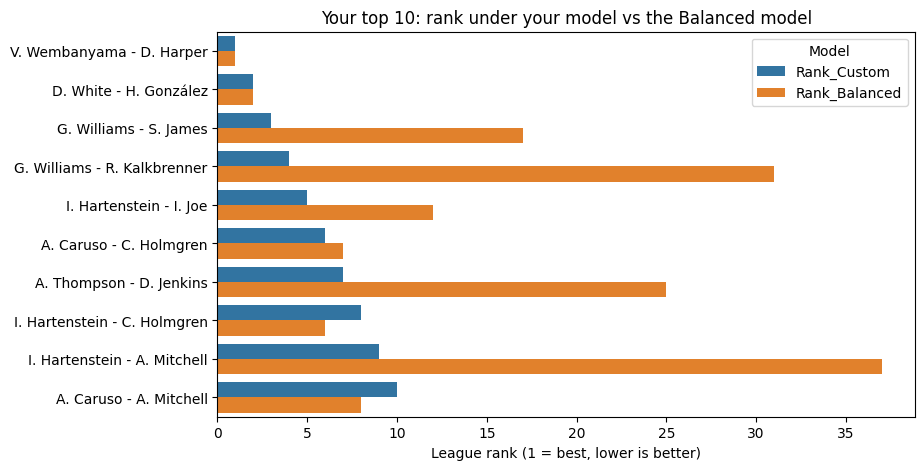

This model favors defense-first, possession-winning duos: DefRtg carries 45.5% of the weight, REB% 27.3%, and NetRtg 18.2%, while TS% contributes just 9.1%. The biggest rise is Hartenstein–A. Mitchell (+28), followed by Williams–Kalkbrenner (+27) and Williams–James (+14); their jumps suggest strong defensive and rebounding profiles under these weights, though the component stats aren’t shown. The largest drops are Hartenstein–Holmgren and Caruso–A. Mitchell (both −2), modest declines that may reflect weaker scores in the newly emphasized categories. Wembanyama–Harper tops the list with a 90.1 custom score and 27.0 NetRtg, while retaining its Balanced-model rank of No. 1. Its overall profile best fits the custom weighting; White–González has slightly higher NetRtg (27.1) but scores lower overall.

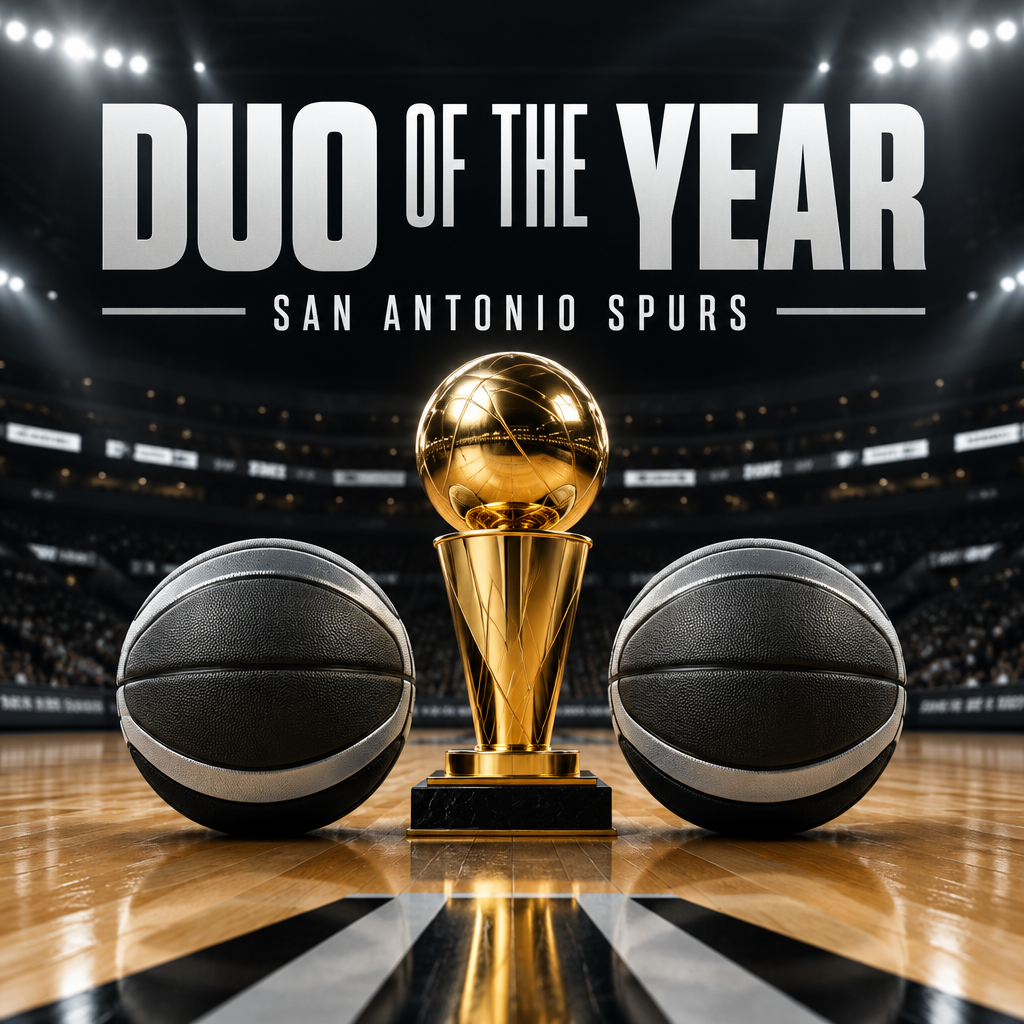

In [17]:
# Example: a user who values defense and rebounding most
my_weights = {'DefRtg': 5, 'REB%': 3, 'NetRtg': 2, 'TS%': 1}
# Or replace this with input, e.g.:
# my_weights = {'DefRtg': float(input("Weight for DefRtg: ")), 'REB%': float(input("Weight for REB%: ")),
#               'NetRtg': float(input("Weight for NetRtg: ")), 'TS%': float(input("Weight for TS%: "))}

explanation_3 = build_your_own_model(my_weights)

## Summary
- **Feature 1** combines our scores, live team results, and OpenAI text + audio into a scouting report for any team.
- **Feature 2** compares any two duos across all four models, adds live player profiles, and has OpenAI explain the verdict.
- **Feature 3** lets the user define efficiency, re-ranks every duo, and uses OpenAI to explain the result and design an award poster.
